# Testing inference: how long must the trigger be?

Retrieval is cued by only a *fragment* of the stored motif. This notebook measures the
minimal **trigger duration** `N_trigger_time` (in ms) such that injecting the first
`N_trigger_time` bins of the target suffices for the network to re-emit the full pattern
in the evoked window. It probes the temporal completeness property of the memory
(pattern completion along time).

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (same weights as notebooks 11/13/14 - no
    retraining here).
2. Single trial with a partial trigger (80 % of `num_delay`) -> F1 + raster.
3. Scan `N_trigger_time = 0 .. num_delay-1` x `N_cv=11` seeded repetitions
    (`get_scores_fraction`) -> per-length F1 (mean +/- std), cached as
    `<datetag>_trigger_time.npz` (+ `.lock`); plot `trigger_time_score.pdf`.

### Main outputs
- cache `../cached_data/<datetag>_trigger_time.npz` (arrays `N_trigger_times`, `scores_np`);
- figures `trigger_time.pdf` (raster) and `trigger_time_score.pdf` (F1 vs trigger length).

### Notes
- `get_input_spikes(N_trigger_time=...)` truncates the cue; `num_delay=41` is the maximum
    (and odd, by construction). With a 80 % trigger (33 ms) retrieval already collapses to
    f1 ~ 0.32 here: the readout needs nearly the full SM window to lock onto the motif.
- The comparison slices are the usual evoked-window convention of notebook 11.
- `scores_np` is `(num_delay, N_cv)` = (41, 11): F1 is the mean +/- s.d. over `N_cv`
    seeded cue realisations (`pattern_object(seed=...)` + `torch.manual_seed`, `seed += 1`
    per repetition, nb 20-style), scored against the clean `frozen_target`. The cache is
    saved after every trigger length, so an interrupted scan can resume.

<!-- MNESIS-annotated -->

In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, trange
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout; the frozen pattern is the same (same seed).
opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


In [3]:
# Full production parameters (see notebook 11's Parameters table).
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=256, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=17.2, fig_height=8.6, phi=1.61803, N_time_show=1000, N_neuron_show=1024, i_pattern=0, N_scan=14, N_cv=11)

In [4]:
# lin (41984 -> 1024 delay-tap readout) + dropout + Leaky; eval() for deterministic probes.
hd.net.eval()

Sequential(
  (lin): Linear(in_features=41984, out_features=1024, bias=False)
  (dropout): Dropout(p=0.6, inplace=False)
  (lif): Leaky()
)

## Retrieval from a partial trigger

Single trial: `N_trigger_time = 0.80 * num_delay` (~33 ms instead of 41). Scored on the
full evoked window against the complete target - the last `0.20 * num_delay` ms of the
motif are never shown to the network and must be completed from memory.

In [5]:
# Partial trigger: get_input_spikes stops copying the target after N_trigger_time bins.

with torch.no_grad():
    target = hd.pattern_object()
    N_trigger_time = int(hd.opt.num_delay*.975)
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=target, N_trigger_time=N_trigger_time)
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]
    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.818	 recall = 0.506	 f1_score = 0.625 


### Raster of the partial-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the green trigger visibly stops
short of the red raster, and the blue re-emission is sparser.

File ../figures/trigger_time.pdf already exists. Skipping save.
File ../figures/trigger_time.png already exists. Skipping save.
File ../figures/trigger_time.svg already exists. Skipping save.


(torch.Size([16, 1024, 1100]), 76.0, 141.0)

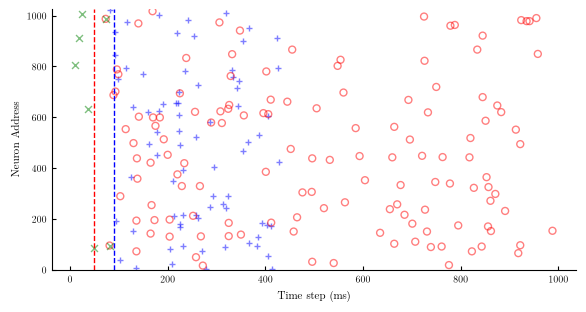

In [6]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'trigger_time', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1 as a function of the trigger duration

`get_scores_fraction`: one forward pass per `N_trigger_time` in `0 .. num_delay-1`,
scoring the evoked window with `get_f1score`. The curve reveals the *critical trigger
length* at which retrieval emerges (and the floor, f1 ~ 0, for spontaneous-only cues).
Cached as `<datetag>_trigger_time.npz` under the `.lock` protocol.

In [7]:
np.arange(1, hd.opt.num_delay+1)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41])

In [8]:
# One cue realisation per repetition (seeded nb 20-style), truncated to N_trigger_time
# bins and scored against the clean frozen_target; the cache is saved after every
# trigger length so an interrupted run can resume from the file.

def get_scores_fraction(N_cv=opt.N_cv):
    N_trigger_times = np.arange(1, hd.opt.num_delay+1)
    scores_np = np.zeros((N_trigger_times.size, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_trigger_time in trange(N_trigger_times.size):
        N_trigger_time = N_trigger_times[i_trigger_time]
        for i_cv in range(N_cv):
            with torch.no_grad():
                torch.manual_seed(seed)
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, N_trigger_time=N_trigger_time)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_trigger_time, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np) # incremental save

    return N_trigger_times, scores_np

# RECOMPUTE = True # overwriting the default value
npy_filename = data_cache / f"{hd.opt.datetag}_trigger_time.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_trigger_times = data['N_trigger_times']
    scores_np = data['scores_np']
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except FileNotFoundError:
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        N_trigger_times, scores_np = get_scores_fraction()
         ##################
        np.savez(npy_filename, N_trigger_times=N_trigger_times, scores_np=scores_np)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_trigger_time.npz


Saving as ../figures/trigger_time_score.pdf
Saving as ../figures/trigger_time_score.png
Saving as ../figures/trigger_time_score.svg


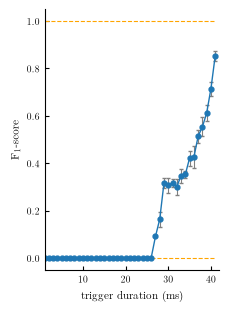

In [9]:
# $F_1$ vs trigger duration (ms), mean +/- std over N_cv realisations; orange guides at 0 and 1.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_trigger_times[0], N_trigger_times[-1], 'orange', ls='--', lw=0.8)
    ax.errorbar(N_trigger_times, scores_np.mean(axis=1), yerr=scores_np.std(axis=1), fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"trigger duration (ms)")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_trigger_times[0], N_trigger_times[-1]+1)
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'trigger_time_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
